Iris Flower Classification

Problem statement:
I want to predict the species of an iris flower from its measurements. The target species are: setosa, versicolor, or virginica. This is classification because the answer is a category.

I chose Iris because it is small and easy to understand. It has 150 flowers and four numeric features: sepal length, sepal width, petal length, and petal width, all measured in centimeters. A sepal is the outer leaf-like part of a flower.

Dataset: https://archive.ics.uci.edu/dataset/53/iris
The goal is to classify similar flowers using a simple logistic regression model.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import f_classif
from scipy.stats import chi2_contingency
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

iris = load_iris()
data = pd.DataFrame(iris.data, columns=['sepal_length', 'sepal_width', 'petal_length', 'petal_width'])
data['species'] = pd.Series(iris.target).map({0: 'setosa', 1: 'versicolor', 2: 'virginica'})
data.to_csv('iris.csv', index=False)
print('Rows and columns:', data.shape)
display(data.head())

Rows and columns: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


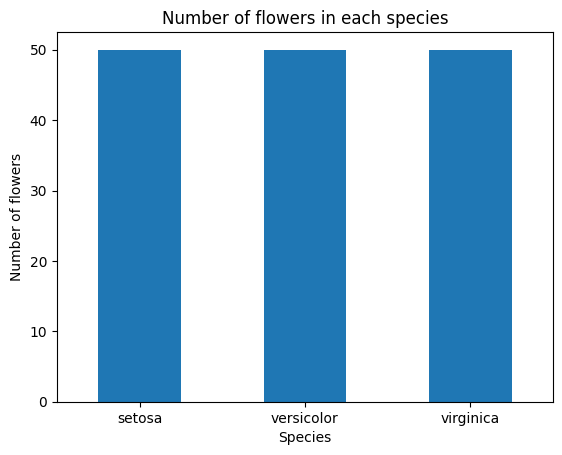

In [2]:
print(data['species'].value_counts())
data['species'].value_counts().plot(kind='bar', rot=0)
plt.title('Number of flowers in each species')
plt.xlabel('Species')
plt.ylabel('Number of flowers')
plt.show()

Each species has 50 flowers, so the original target is very balanced. No oversampling or undersampling is needed.

Basic data cleaning
I will check data types, missing values, duplicates, and category labels. There is no unwanted input column in this dataset. Species is the target, so it won't be included among the predictors.

In [3]:
print(data.dtypes)
print('Missing values:')
print(data.isnull().sum())

sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species             str
dtype: object
Missing values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


All four measurement columns are numeric. Every column has zero missing values, so no filling or row removal for missing data is needed

Next i removed exact duplicate rows and standardize the species labels by trimming spaces and using lowercase.

In [4]:
print('Duplicates before:', data.duplicated().sum())
data = data.drop_duplicates().copy()
print('Duplicates after:', data.duplicated().sum())
print('Labels before:', data['species'].unique())
data['species'] = data['species'].str.strip().str.lower()
print('Labels after:', data['species'].unique())
print('Rows remaining:', len(data))

Duplicates before: 1
Duplicates after: 0
Labels before: <ArrowStringArray>
['setosa', 'versicolor', 'virginica']
Length: 3, dtype: str
Labels after: <ArrowStringArray>
['setosa', 'versicolor', 'virginica']
Length: 3, dtype: str
Rows remaining: 149


One duplicate was removed, leaving 149 flowers. The three labels were already consistent. Identical measurements can occur naturally, but I remove the exact duplicate to meet the assignment requirements!

Split before learning cleaning rules
I reserve 20% of the flowers for testing. Stratification keeps similar species proportions in both groups. Outlier limits, feature selection, and scaling will use training data only. The test data will stay unchanged so the final score includes unusual flowers as well.

In [5]:
train, test = train_test_split(data, test_size=0.2, random_state=42, stratify=data['species'])
train = train.copy()
test = test.copy()
numeric = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
print('Training rows:', len(train))
print('Test rows:', len(test))
print('Training classes:')
print(train['species'].value_counts())

Training rows: 119
Test rows: 30
Training classes:
species
setosa        40
versicolor    40
virginica     39
Name: count, dtype: int64


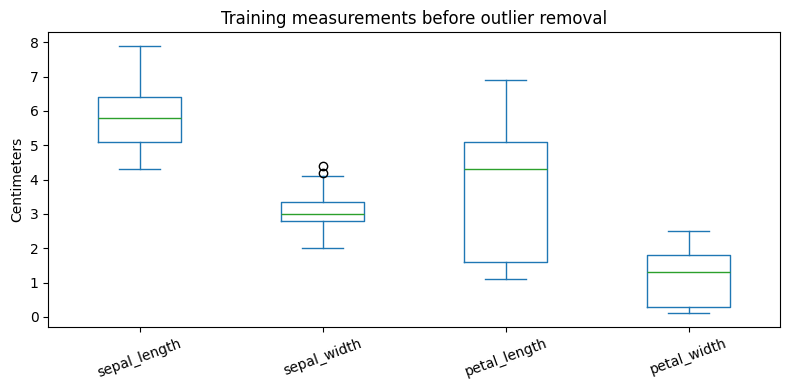

In [6]:
train[numeric].plot(kind='box', figsize=(8, 4))
plt.title('Training measurements before outlier removal')
plt.ylabel('Centimeters')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

The boxplot shows high sepal-width values. I use the 1.5 times iqr rule: values below q1 − 1.5 times iqr or above q3 plus 1.5 times iqr are flagged. I removed training rows I used earlier.

In [7]:
q1 = train[numeric].quantile(0.25)
q3 = train[numeric].quantile(0.75)
iqr = q3 - q1
outliers = ((train[numeric] < q1 - 1.5 * iqr) | (train[numeric] > q3 + 1.5 * iqr)).any(axis=1)
print('Outlier rows removed:', outliers.sum())
display(train[outliers])
train = train[~outliers].copy()
print('Training rows remaining:', len(train))
print('Test rows unchanged:', len(test))

Outlier rows removed: 2


,sepal_length,sepal_width,petal_length,petal_width,species
15,5.7,4.4,1.5,0.4,setosa
33,5.5,4.2,1.4,0.2,setosa


Training rows remaining: 117
Test rows unchanged: 30


Two training flowers were flagged because their sepal widths were 4.4 and 4.2 cm. There are now 117 training flowers and 30 test flowers.

Feature engineering
Numeric target and dummy variables
I convert species to numeric labels: setosa = 0, versicolor = 1, virginica = 2. These numbers are just class names, there's no specific order. All predictors are numeric, so dummy variables are'mt needed

In [8]:
labels = {'setosa': 0, 'versicolor': 1, 'virginica': 2}
X_train = train[numeric].copy()
X_test = test[numeric].copy()
y_train = train['species'].map(labels)
y_test = test['species'].map(labels)
print('Class codes:', labels)
print('Training class counts:')
print(y_train.value_counts().sort_index())
print('Missing target codes:', y_train.isnull().sum() + y_test.isnull().sum())

Class codes: {'setosa': 0, 'versicolor': 1, 'virginica': 2}
Training class counts:
species
0    38
1    40
2    39
Name: count, dtype: int64
Missing target codes: 0


The training counts are 38, 40, and 39, so the data are still almost balanced. No balancing is needed.

Feature selection: variance and ANOVA

A constant feature cannot help distinguish flowers. I check each feature’s variance. Then I use ANOVA to compare the species means. A larger F score means the differences between species are larger relative to variation within species. A small p value is evidence that the species means are not all equal. I use p < 0.05 as a simple screening rule. This does not prove causation or guarantee prediction quality.

In [9]:
print('Feature variance:')
print(X_train.var().round(3))
print('Constant features:', X_train.columns[X_train.var() == 0].tolist())

Feature variance:
sepal_length    0.723
sepal_width     0.174
petal_length    3.098
petal_width     0.579
dtype: float64
Constant features: []


In [10]:
f_scores, p_values = f_classif(X_train, y_train)
anova = pd.DataFrame({'F_score': f_scores, 'p_value': p_values}, index=numeric)
display(anova.sort_values('F_score', ascending=False))
selected = anova.index[anova['p_value'] < 0.05].tolist()
print('Features passing ANOVA:', selected)

,F_score,p_value
petal_length,899.403255,1.542862e-70
petal_width,770.674585,5.846130e-67
sepal_length,103.419322,2.427931e-26
sepal_width,39.529387,9.104842e-14


Features passing ANOVA: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']


No feature has zero variance. Sepal width has the smallest variance, but variance alone does not show usefulness because the measurement ranges differ.

All four ANOVA p values are below 0.05, so I keep them at this stage. Petal length has the largest f score (about 899), followed by petal width (about 771). Sepal width has the smallest f score (about 40), but it still passes the screening rule.

Chi-squared check
Chi-squared tests association between categories. Since the measurements are continuous, I temporarily divide each one into a lower and upper half using training data. I compare these groups with species. A p value below 0.05 suggests association. These groups are only for this check, the model will use the original measurements.

In [11]:
chi_results = []
for column in numeric:
    groups = pd.qcut(X_train[column], q=2, duplicates='drop')
    table = pd.crosstab(groups, y_train)
    score, p, dof, expected = chi2_contingency(table)
    chi_results.append([column, score, p, expected.min()])
chi_table = pd.DataFrame(chi_results, columns=['feature', 'chi_squared', 'p_value', 'smallest_expected_count'])
display(chi_table)

,feature,chi_squared,p_value,smallest_expected_count
0,sepal_length,59.859748,1.003739e-13,18.188034
1,sepal_width,38.774949,3.803005e-09,17.213675
2,petal_length,77.097085,1.813764e-17,18.837607
3,petal_width,78.462053,9.166039e-18,17.863248


All four grouped measurements have p values below 0.05. The smallest expected counts are all above 5, so there is no sparse cell problem for this check. No feature is removed by this test.

Correlated features
I check correlations among predictors. For a simple reduction rule, if a pair has an absolute correlation above 0.90, I keep the feature with the higher ANOVA f score. Highly correlated features can contain similar information.

,sepal_length,sepal_width,petal_length,petal_width
sepal_length,1.000,-0.142,0.891,0.827
sepal_width,-0.142,1.000,-0.397,-0.332
petal_length,0.891,-0.397,1.000,0.963
petal_width,0.827,-0.332,0.963,1.000


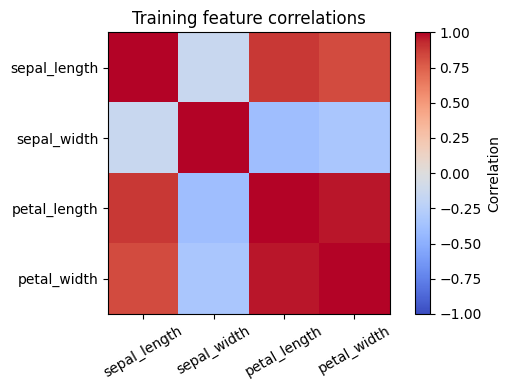

In [12]:
correlation = X_train.corr()
display(correlation.round(3))
plt.figure(figsize=(6, 4))
plt.imshow(correlation, cmap='coolwarm', vmin=-1, vmax=1)
plt.xticks(range(4), numeric, rotation=30)
plt.yticks(range(4), numeric)
plt.colorbar(label='Correlation')
plt.title('Training feature correlations')
plt.tight_layout()
plt.show()

Petal length and petal width have a correlation of 0.963, above my 0.90 cutoff. I drop petal width because petal length has the higher ANOVA f score. This reduces the model from four inputs to three. Correlation does not prove a feature is useless, this is a simple choice to reduce similar information.

Feature scaling
I standardize the remaining inputs by subtracting the training mean and dividing by the training standard deviation. Logistic regression can run without scaling, but scaling helps its optimization and makes its regularization more comparable across inputs. I fit the scaler on training data and use those same values for the test data.

In [13]:
selected.remove('petal_width')
X_train = X_train[selected]
X_test = X_test[selected]
print('Final features:', selected)
print('Training shape:', X_train.shape)
print('Test shape:', X_test.shape)

Final features: ['sepal_length', 'sepal_width', 'petal_length']
Training shape: (117, 3)
Test shape: (30, 3)


In [14]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
scaled = pd.DataFrame(X_train_scaled, columns=selected)
print('Training means after scaling:')
print(scaled.mean().round(3))
print('Training standard deviations after scaling:')
print(scaled.std(ddof=0).round(3))

Training means after scaling:
sepal_length   -0.0
sepal_width     0.0
petal_length    0.0
dtype: float64
Training standard deviations after scaling:
sepal_length    1.0
sepal_width     1.0
petal_length    1.0
dtype: float64


The scaled training means are approximately 0 and the standard deviations are 1, as I basically expected.

Prediction model
I use logistic regression because this is a small classification problem with numeric inputs. Despite its name, logistic regression predicts categories. It learns a weighted score for each species, converts the scores into probabilities, and predicts the species with the highest probability. Training adjusts the weights to reduce prediction errors.

I use the fixed 80/20 train/test split instead of cross-validation to keep this project simple. I do not tune the model using the test set.

I evaluate accuracy, precision, recall, f1 score, and a confusion matrix. Accuracy is the fraction correct. Precision measures how often a predicted species is correct. Recall measures how many flowers of a species were found. f1 combines precision and recall. r squared is not appropriate because this is classification.

In [15]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)
print('Model:', model)
print('Training accuracy:', round(model.score(X_train_scaled, y_train), 3))

Model: LogisticRegression(max_iter=1000)
Training accuracy: 0.957


In [16]:
predictions = model.predict(X_test_scaled)
accuracy = accuracy_score(y_test, predictions)
baseline = (y_test == y_train.mode()[0]).mean()
print('Test flowers:', len(y_test))
print('Correct predictions:', (y_test == predictions).sum())
print('Test accuracy:', round(accuracy, 3))
print('Majority-class baseline accuracy:', round(baseline, 3))

Test flowers: 30
Correct predictions: 27
Test accuracy: 0.9
Majority-class baseline accuracy: 0.333


In [17]:
print(classification_report(y_test, predictions, target_names=iris.target_names, zero_division=0))

              precision    recall  f1-score   support

      setosa       1.00      0.90      0.95        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.90        30
   macro avg       0.91      0.90      0.90        30
weighted avg       0.91      0.90      0.90        30



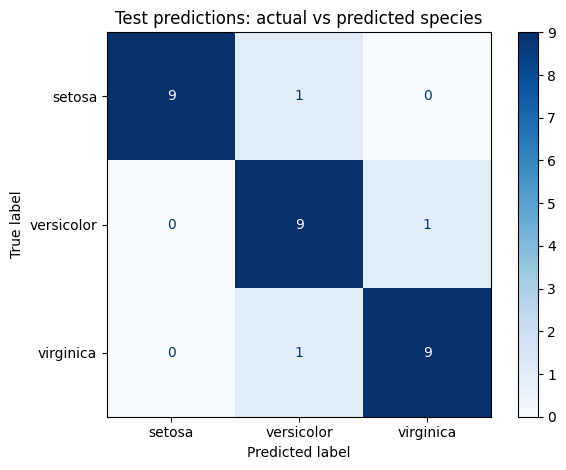

In [18]:
ConfusionMatrixDisplay.from_predictions(y_test, predictions, display_labels=iris.target_names, cmap='Blues')
plt.title('Test predictions: actual vs predicted species')
plt.tight_layout()
plt.show()

Results and limitations

The model correctly predicted 27 of 30 test flowers: 90% accuracy? This is above the majority-class baseline of 33.3%. Training accuracy was 95.7%. The macro f1 score is about 0.90.

The confusion matrix has nine correct flowers for each species on the diagonal. One setosa was predicted as versicolor, one versicolor as virginica, and one virginica as versicolor. Each species has recall of 0.90.

The score is not low for this small classroom example, so the model did not fail overall. The mistakes could come from overlapping measurements, the simple linear boundaries, or information lost when dropping petal width. This analysis does not establish which cause explains each mistake.

There are only 30 test flowers, so one additional error would change accuracy by about 3.3 percentage points. One split does not prove the same performance on new populations. Removing unusual training flowers can also discard useful information. A future improvement would be to compare feature choices with cross-validation on the training set and then evaluate once on a separate test set.